# Metropolis and Langevin sampling

**Gabriel Trabelsi**

Implementations of random-walk Metropolis and MALA for a Gaussian target, followed by the completed posterior-sampling code from the same practical session.

**Academic context:** UM4MA379, Statistique Computationnelle, Sorbonne Université, Master 1, 2025-2026. Course: A. Guyader; practical sessions: M. Sangnier. Implementations and completed experiments by Gabriel Trabelsi, developed within the supplied exercise framework.

Figures and outputs are retained from the original notebook. Random draws and timings may differ on a new run; historical execution counters have been cleared.

In [ ]:
import numpy as np  # Vectors and matrices
from scipy import stats  # Probability distributions
import matplotlib.pyplot as plt  # Plots

# Enable nice plots
import matplotlib as mpl
try:
    mpl.style.use('seaborn-v0_8')
except:
    mpl.style.use('seaborn')
mpl.rcParams['image.cmap'] = 'plasma'
nice_hist = dict(bins='auto', density=True, ec='w')


## 1. Random-walk Metropolis

The proposal adds a symmetric uniform increment. The function returns the chain and the acceptance rate.

In [ ]:
n = 10**4
unif = stats.uniform()
norm = stats.norm

def sample_metropolis(kernel, size=1, init=0.):
    sample_u = kernel.rvs(size=size)    # incréments ~ U du problème
    sample_a = unif.rvs(size=size)      # uniformes [0,1] pour acceptation

    sample = np.empty(size + 1)
    sample[0] = init
    n_accept = 0

    for k in range(size):
        prop = sample[k] + sample_u[k]
        ratio = norm.pdf(prop) / norm.pdf(sample[k])

        if sample_a[k] <= min(1, ratio):
            sample[k+1] = prop
            n_accept += 1
        else:
            sample[k+1] = sample[k]

    return sample, n_accept / size

# Application
n = 10**4
X0 = stats.uniform(loc=-3, scale=6).rvs()
chain, accept_rate = sample_metropolis(
    kernel=stats.uniform(loc=-0.5, scale=1),
    size=n,
    init=X0
)
print(f"Taux d'acceptation : {accept_rate:.3f}")


Taux d'acceptation : 0.905


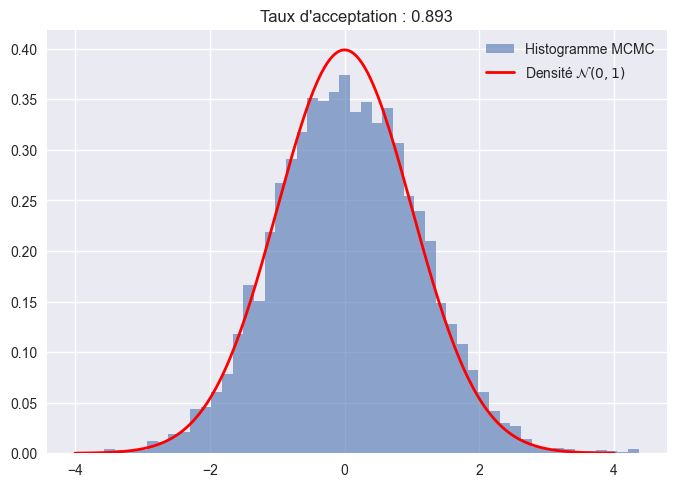

In [ ]:
norm = stats.norm()
kernel = stats.uniform(loc=-0.5, scale=1)   # U([-1/2, 1/2])

x = np.linspace(-4, 4, 200)

chain, rate = sample_metropolis(kernel, size=n, init=0.)

plt.hist(chain, bins=50, density=True, alpha=0.6, label="Histogramme MCMC")
plt.plot(x, norm.pdf(x), 'r-', lw=2, label=r"Densité $\mathcal{N}(0,1)$")
plt.legend()
plt.title(f"Taux d'acceptation : {rate:.3f}")
plt.show()


## 2. Initialization away from the target

The original experiment starts at 20. The displayed histogram includes the initial transient.

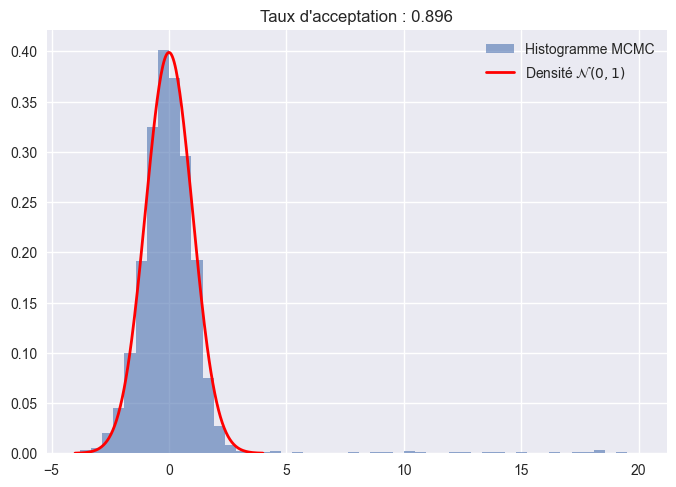

In [ ]:
norm = stats.norm()
kernel = stats.uniform(loc=-0.5, scale=1)   # U([-1/2, 1/2])

x = np.linspace(-4, 4, 200)

chain, rate = sample_metropolis(kernel, size=n, init=20)

plt.hist(chain, bins=50, density=True, alpha=0.6, label="Histogramme MCMC")
plt.plot(x, norm.pdf(x), 'r-', lw=2, label=r"Densité $\mathcal{N}(0,1)$")
plt.legend()
plt.title(f"Taux d'acceptation : {rate:.3f}")
plt.show()


## 3. MALA

For the Gaussian target, the proposal is $y=x-\sigma^2x/2+\sigma\epsilon$. The acceptance correction includes the forward and reverse proposal densities.

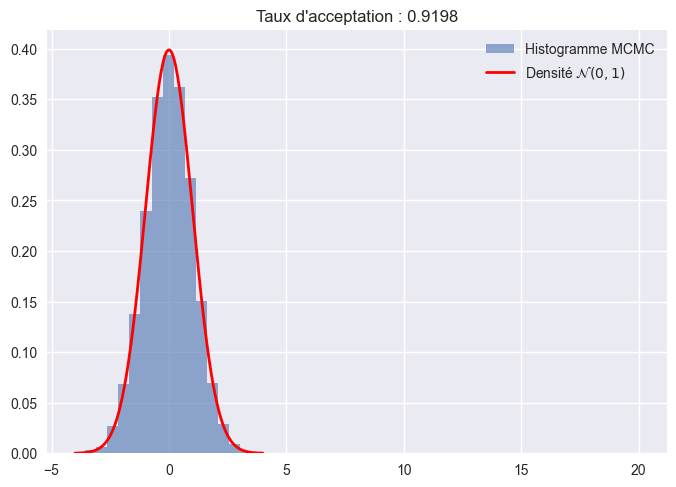

In [ ]:
n = 10**4

# Loi cible N(0, 1), sa densité non-normalisée et sa dérivée
norm = stats.norm()
f = lambda x: np.exp(-x**2/2)
f_der = lambda x: -x*np.exp(-x**2/2)
# Noyau non-normalisé q(x, y, sigma)
q = lambda x, y, sigma: np.exp(-(y - x + sigma**2 * x / 2)**2 / (2 * sigma**2))

def sample_mala(size=1, init=0., sigma=1.):
    unif = stats.uniform()
    threshold = unif.rvs(size=size)  # Array of the n thresholds U_i
    move = stats.norm().rvs(size=size)  # Array of the n moves from the current position

    sample = [init]

    n_acc = 0

    for i in range(size):
        pos = sample[-1]
        prop = pos - pos*sigma**2 * 1/2 + sigma * move[i]

        if threshold[i] <= min(1, ( f(prop) * q(prop, pos, sigma) ) / ( f(pos) * q(pos, prop, sigma))):
            sample.append(prop)
            n_acc += 1
        else:
            sample.append(pos)

    return np.asarray(sample), n_acc/size

chain, rate_mala = sample_mala(size=n, init=20)

plt.hist(chain, bins=50, density=True, alpha=0.6, label="Histogramme MCMC")
plt.plot(x, norm.pdf(x), 'r-', lw=2, label=r"Densité $\mathcal{N}(0,1)$")
plt.legend()
plt.title(f"Taux d'acceptation : {rate_mala}")
plt.show()


## 4. Posterior sampling for a mixture weight

The following completed code compares prior-based importance sampling, an independent Metropolis proposal and a local wrapped proposal. The saved posterior outputs are omitted because their recorded values are inconsistent across cells, suggesting that they were not all produced in one sequential run. The code is retained for inspection and rerunning.

The local proposal uses `1/sqrt(m)`, where `m` is the chain length; this is the implementation actually present in the source.

In [ ]:
# A priori
prior = stats.uniform()
theta0 = prior.rvs()

# Lois utiles
ber = stats.bernoulli(theta0)
normp = stats.norm(loc=1)
normm = stats.norm(loc=-1)

n = 50000
# Simulation de X
bern_sample = ber.rvs(size=n)
X = stats.norm(loc=1*bern_sample -1*(1-bern_sample)).rvs()

print(f'theta0 = {theta0}')
plt.hist(X, **nice_hist);


In [ ]:
N = 5000

theta_sample = prior.rvs(size=N)

log_L = lambda X, theta: np.sum(np.log(theta[:, None] * normp.pdf(X[None, :]) + (1-theta[:, None]) * normm.pdf(X[None, :])), axis=1)

logL = log_L(X, theta_sample)
logL -= logL.max()
L = np.exp(logL)

estMc = np.cumsum(theta_sample * L) / np.cumsum(L)

# Figure
plt.plot(np.arange(1, N+1), estMc, label="Estimateur MC")
plt.axhline(theta0, color="red", label="$\\theta_0$")
plt.ylim(0, 1)
plt.legend();


In [ ]:
m = 10**4
init = 0.5

threshold = prior.rvs(size=m-1)
move = prior.rvs(size=m-1)
n_accept = 0

sample = [init]
for i in range(m-1):
    pos = sample[-1]
    prop = move[i]

    log_ratio = log_L(X, np.array([prop]))[0] - log_L(X, np.array([pos]))[0]

    if np.log(threshold[i]) <= min(0, log_ratio):
        sample.append(prop)
        n_accept += 1
    else:
        sample.append(pos)

plt.hist(sample, **nice_hist)
print(f"Taux d'acceptation : {n_accept / (m-1):.2f}")

burn = 500

# Metropolis (burn-in nécessaire)
sample_arr = np.array(sample[burn:])
est_metropolis = np.cumsum(sample_arr) / np.arange(1, len(sample_arr) + 1)

# MC classique (pas de burn-in, c'est iid)
est_mc = np.cumsum(theta_sample * L) / np.cumsum(L)

# Figure
plt.figure(figsize=(10, 5))
plt.plot(est_metropolis, label="Metropolis")
plt.plot(est_mc, label="MC classique")
plt.axhline(theta0, color="red", linestyle="--", label=r"$\theta_0$")
plt.ylim(0, 1)
plt.legend()
plt.xlabel("Itérations")
plt.ylabel(r"$\hat{\theta}$");

print(np.mean(sample))


In [ ]:
m = 10**4
init = 0.5

threshold = prior.rvs(size=m-1)
move = prior.rvs(size=m-1)*2 - 1
n_accept = 0

sample = [init]
for i in range(m-1):
    pos = sample[-1]
    prop = (pos + 1/np.sqrt(m) * move[i])%1

    log_ratio = log_L(X, np.array([prop]))[0] - log_L(X, np.array([pos]))[0]

    if np.log(threshold[i]) <= min(0, log_ratio):
        sample.append(prop)
        n_accept += 1
    else:
        sample.append(pos)

plt.hist(sample, **nice_hist)
print(f"Taux d'acceptation : {n_accept / (m-1):.2f}")
print(np.mean(sample))
print(theta0)


## Limits

Acceptance rate and a marginal histogram are limited diagnostics. This notebook does not report effective sample size, multi-chain diagnostics or a runtime-normalized comparison. The Gaussian implementation evaluates densities directly and may underflow far into the tails.